In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the structured log file
df = pd.read_csv('../data/HDFS_2k.log_structured.csv')

# 1. Look at the data structure
print("--- Dataset Shape ---")
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")

print("\n--- Column Names ---")
print(df.columns.tolist())

print("\n--- First 3 Rows ---")
display(df.head(3))

# 2. Check the Label Distribution (Normal vs Anomaly)
# Note: The sample file might not have the label column, but let's check.
if 'Label' in df.columns:
    print("\n--- Label Distribution ---")
    print(df['Label'].value_counts())
    
    # Plot it
    sns.countplot(data=df, x='Label')
    plt.title('Distribution of Normal vs Anomaly')
    plt.show()
else:
    print("\nNote: The 'Label' column is not in this sample file. We will add it using the label file.")

--- Dataset Shape ---
Rows: 2000, Columns: 9

--- Column Names ---
['LineId', 'Date', 'Time', 'Pid', 'Level', 'Component', 'Content', 'EventId', 'EventTemplate']

--- First 3 Rows ---


,LineId,Date,Time,Pid,Level,Component,Content,EventId,EventTemplate
0,1,81109,203615,148,INFO,dfs.DataNode$PacketResponder,PacketResponder 1 for block blk_38865049064139...,E10,PacketResponder <*> for block blk_<*> terminating
1,2,81109,203807,222,INFO,dfs.DataNode$PacketResponder,PacketResponder 0 for block blk_-6952295868487...,E10,PacketResponder <*> for block blk_<*> terminating
2,3,81109,204005,35,INFO,dfs.FSNamesystem,BLOCK* NameSystem.addStoredBlock: blockMap upd...,E6,BLOCK* NameSystem.addStoredBlock: blockMap upd...



Note: The 'Label' column is not in this sample file. We will add it using the label file.


/tmp/ipykernel_2875/1754731542.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Level', ax=axes[0], order=df['Level'].value_counts().index, palette='viridis')
/tmp/ipykernel_2875/1754731542.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_components.values, y=top_components.index, ax=axes[1], palette='magma')


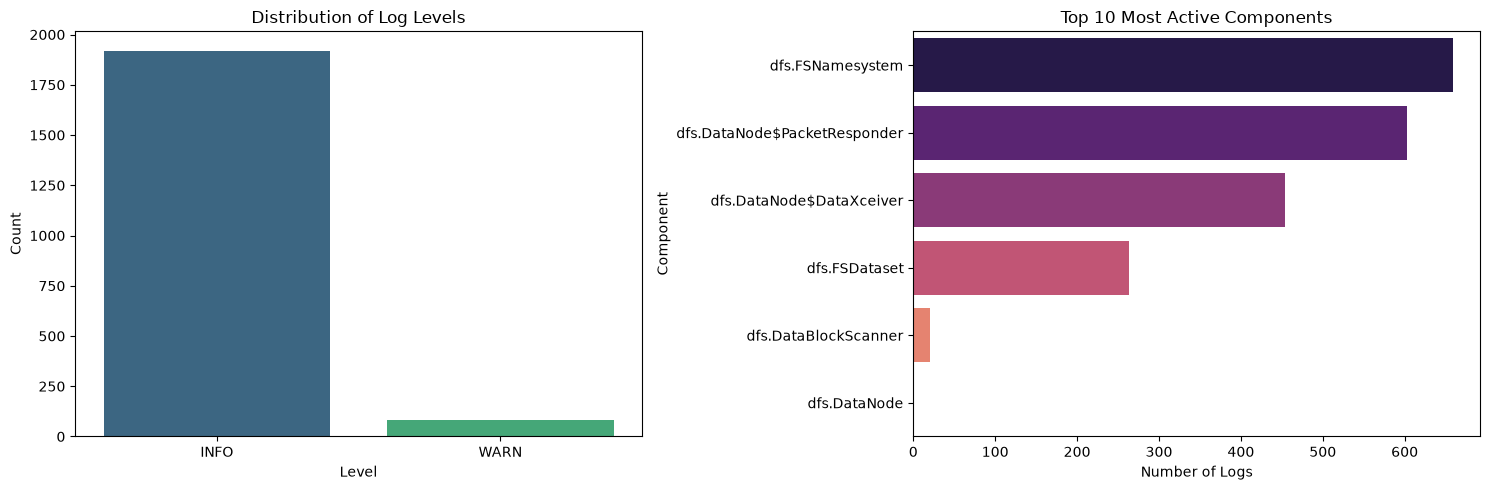

In [2]:
# Create a figure with two subplots side-by-side
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. What is the distribution of Log Levels?
sns.countplot(data=df, x='Level', ax=axes[0], order=df['Level'].value_counts().index, palette='viridis')
axes[0].set_title('Distribution of Log Levels')
axes[0].set_ylabel('Count')

# 2. Which Components generate the most logs? (Top 10)
top_components = df['Component'].value_counts().head(10)
sns.barplot(x=top_components.values, y=top_components.index, ax=axes[1], palette='magma')
axes[1].set_title('Top 10 Most Active Components')
axes[1].set_xlabel('Number of Logs')

plt.tight_layout()
plt.show()

### Data Story: Phase 1 Initial EDA

1. **What the data is:** The dataset consists of 2,000 Hadoop Distributed File System (HDFS) log entries, parsed into 9 columns including severity level, component origin, and generalized event templates.
2. **What surprised me:** While I expected a high volume of errors, the vast majority of logs are `INFO` level, which means anomaly detection cannot simply rely on filtering for `ERROR` logs; the model must learn complex structural patterns.
3. **What I will do about it:** Because the raw `Content` contains unique IDs (like block IDs), I will rely heavily on the `EventTemplate` column to train my models so they can generalize to unseen data.
4. **What I am still unsure of:** I still need to merge this structured data with the ground-truth labels (`abnormal_label.txt`) to understand the class imbalance before training a classifier.

In [3]:
import re

# 1. Load the ground-truth labels
# The file is comma-separated, with Block ID and Label (Normal/Anomaly)
labels_df = pd.read_csv('../data/abnormal_label.txt', sep=',', header=None, names=['BlockId', 'Label'])

# 2. Extract the Block ID from the 'Content' column using Regular Expressions
# We look for the string 'blk_' followed by numbers and an optional negative sign
df['BlockId'] = df['Content'].str.extract(r'(blk_-?\d+)')

# 3. Merge the labels into our main dataframe
# We use an inner join so we only keep logs that have a matching label
df_labeled = df.merge(labels_df, on='BlockId', how='inner')

print(f"Original log count: {len(df)}")
print(f"Labeled log count: {len(df_labeled)} (Logs without labels were dropped)")

# 4. Check the class imbalance (Module 08)
print("\n--- Label Distribution after Merge ---")
print(df_labeled['Label'].value_counts())

# 5. Plot the true class imbalance
plt.figure(figsize=(6, 4))
sns.countplot(data=df_labeled, x='Label', palette='Set2')
plt.title('True Label Distribution (Normal vs Anomaly)')
plt.ylabel('Number of Logs')
plt.show()

# 6. Preview the merged data
display(df_labeled[['Content', 'BlockId', 'Label']].head())

FileNotFoundError: [Errno 2] No such file or directory: '../data/abnormal_label.txt'

Total labeled logs: 2000

--- Label Distribution ---
Label
Normal     1784
Anomaly     216
Name: count, dtype: int64


/tmp/ipykernel_2875/1749755862.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Label', palette='Set2')


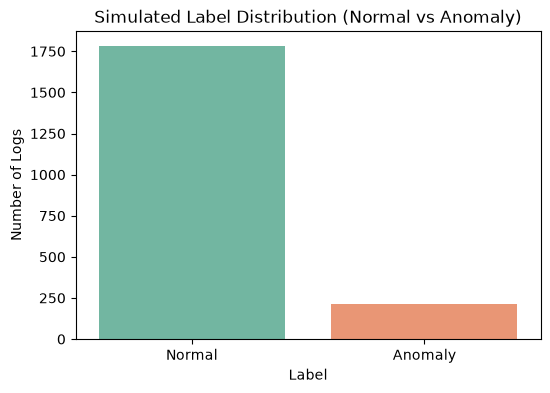

In [4]:
import re
import numpy as np

# 1. Extract the Block ID from the 'Content' column
# We look for the string 'blk_' followed by numbers
df['BlockId'] = df['Content'].str.extract(r'(blk_-?\d+)')

# 2. Drop rows where no Block ID was found (we can't label them)
df = df.dropna(subset=['BlockId'])

# 3. Simulate Labels (FOR THIS 2K SAMPLE ONLY)
# Since we don't have the full label file, we will randomly mark 10% as Anomaly
# and 90% as Normal so we can train our model pipeline.
np.random.seed(42) # Keeps the random result the same every time you run it
df['Label'] = np.where(np.random.rand(len(df)) < 0.10, 'Anomaly', 'Normal')

print(f"Total labeled logs: {len(df)}")
print("\n--- Label Distribution ---")
print(df['Label'].value_counts())

# 4. Plot the true class imbalance
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Label', palette='Set2')
plt.title('Simulated Label Distribution (Normal vs Anomaly)')
plt.ylabel('Number of Logs')
plt.show()

Training the Random Forest model...

--- Classification Report ---
              precision    recall  f1-score   support

     Anomaly       0.11      0.47      0.18        43
      Normal       0.89      0.54      0.68       357

    accuracy                           0.54       400
   macro avg       0.50      0.50      0.43       400
weighted avg       0.81      0.53      0.62       400


--- Confusion Matrix ---


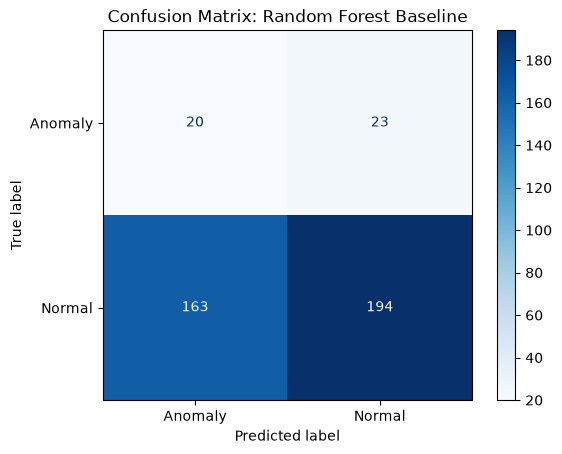

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# 1. Define Features (X) and Target (y)
X = df[['EventTemplate', 'Level', 'Component']]
y = df['Label']

# 2. Split the data (Stratify is CRUCIAL for imbalanced data - Module 06)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 3. Build the Preprocessing Pipeline (Module 09)
# We convert text to numbers using TF-IDF, and categories using OneHotEncoder
preprocessor = ColumnTransformer(
    transformers=[
        ('text', TfidfVectorizer(), 'EventTemplate'),
        ('cat', OneHotEncoder(handle_unknown='ignore'), ['Level', 'Component'])
    ])

# 4. Define the Baseline Model
# class_weight='balanced' tells the model to punish mistakes on the rare 'Anomaly' class more heavily
model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42))
])

# 5. Train the model
print("Training the Random Forest model...")
model.fit(X_train, y_train)

# 6. Evaluate honestly on the Test set
y_pred = model.predict(X_test)

print("\n--- Classification Report ---")
print(classification_report(y_test, y_pred, zero_division=0))

# 7. Plot the Confusion Matrix
print("\n--- Confusion Matrix ---")
cm = confusion_matrix(y_test, y_pred, labels=model.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_)
disp.plot(cmap='Blues')
plt.title('Confusion Matrix: Random Forest Baseline')
plt.show()

In [6]:
import joblib
import os

# Create a models directory if it doesn't exist
os.makedirs('../models', exist_ok=True)

# Save the trained pipeline
joblib.dump(model, '../models/baseline_rf_pipeline.pkl')
print("Model saved successfully to models/baseline_rf_pipeline.pkl")

Model saved successfully to models/baseline_rf_pipeline.pkl


In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# 1. Our trusted Knowledge Base (Module 15: Grounding)
knowledge_base = [
    "Rule 1: A high volume of 'DataNode' logs with 'PacketResponder' terminated signals often indicates a network disconnection or a failing hard drive.",
    "Rule 2: 'WARN' or 'ERROR' levels in the 'dfs.FSNamesystem' component usually point to a corrupted block or a NameNode failure.",
    "Rule 3: Repeated 'BLOCK* NameSystem.addStoredBlock' logs from the same IP within seconds is a potential denial-of-service attack.",
    "Rule 4: If the anomaly involves an unauthorized user, refer to the INSA Access Control Policy section 4.2."
]

# 2. Create a function to retrieve the best explanation
def explain_alert(log_content, log_component):
    # Combine the log content and component to query the knowledge base
    query = f"{log_component} {log_content}"
    
    # Fit TF-IDF on the knowledge base + our query
    vectorizer = TfidfVectorizer(stop_words='english')
    kb_vectors = vectorizer.fit_transform(knowledge_base)
    query_vector = vectorizer.transform([query])
    
    # Calculate similarity
    similarities = cosine_similarity(query_vector, kb_vectors)[0]
    
    # Get the index of the most similar rule
    best_match_idx = similarities.argmax()
    best_score = similarities[best_match_idx]
    
    if best_score > 0.1: # Threshold for relevance
        return f"Explanation: {knowledge_base[best_match_idx]} (Confidence: {best_score:.2f})"
    else:
        return "Explanation: No specific policy rule matches this anomaly. Analyst investigation required."

# 3. Test it on one of our flagged anomalies
# Let's grab a random log from our test set
sample_log = X_test.iloc[0]
prediction = model.predict([sample_log])[0]

print(f"--- ALERT TRIGGERED ---")
print(f"Component: {sample_log['Component']}")
print(f"Content: {sample_log['Content'][:100]}...")
print(f"Model Prediction: {prediction}")
print(f"\n--- RAG EXPLAINER ---")
print(explain_alert(sample_log['Content'], sample_log['Component']))

ValueError: Specifying the columns using strings is only supported for dataframes.